# Identification and classification of solar flares
## Using X-ray Light Curves with GOES XRS and Chandrayaan-2 XSM

In this exercise, we will learn how to use the X-ray flux from the Sun to identify and classify solar flares. 
We will use the X-ray observations from [GOES XRS](https://www.swpc.noaa.gov/products/goes-x-ray-flux) and [Chandrayaan-2 XSM](https://www.prl.res.in/ch2xsm/) instruments. 

We will then look at the corresponding Extreme Ultraviolet (EUV) images of the Sun during that period to identify the flare location on the solar disk. For EUV observations, we will use the data from SDO AIA instrument through [helioviewer](https://gs671-suske.ndc.nasa.gov/) interface. Here is an alternate link to [helioviewer](https://helioviewer.ias.u-psud.fr/).

To see how to download the data from GOES and XSM, please see [APPENDIX](#appendix)

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from datetime import datetime, timedelta

from astropy.visualization import time_support
from sunpy import timeseries as ts

import glob

### Read and plot X-ray flux data from GOES XRS

The daily 1-minute average GOES-16 XRS flux data has been provided in netcdf files downloaded from the GOES data archive. This is a single file for the entire missiong life of GOES 16 XRS instrument. The data will be read and plotted using Sunpy package modules.

/home/mithun/miniconda3/envs/work/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


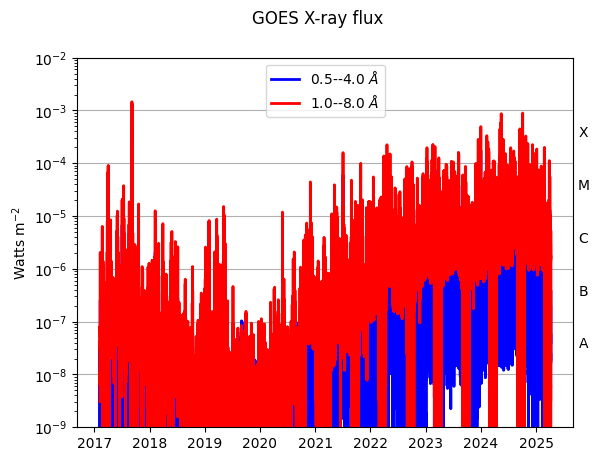

In [2]:
file_goes='sci_xrsf-l2-avg1m_g16_s20170207_e20250407_v2-2-2.nc'
goesData = ts.TimeSeries(file_goes, concatenate=True)

# A quick look at the data
goesData.peek()


Plot the XRS B channel data (1-8 Ang) which is used for flare classification. There is also a flag stating whether the data quality is good, so the data should also be filtered with that to get only good quality measurements. 

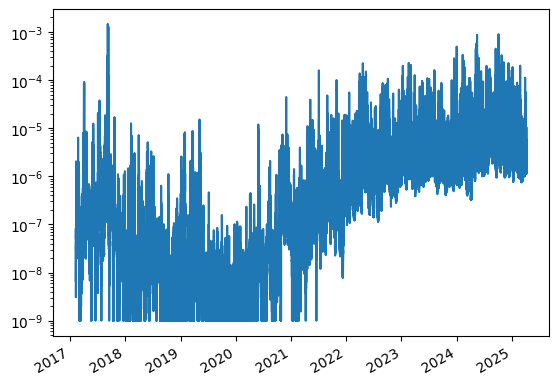

In [3]:
# convert the data into a data frame to make it easier for further analysis
goesdf = goesData.to_dataframe()

## filter times with good quality data
goesdfFilt = goesdf[(goesdf["xrsa_quality"] == 0) & (goesdf["xrsb_quality"] == 0)]
goesdfFilt['xrsb'].plot()
plt.yscale('log')
plt.show()

### Read and plot X-ray flux data from XSM

The XSM flux data for the entire duration from Sep 2019 till April 2025 is provided in a text file having four columns for mission elapse time (number of seconds from 2017 Jan 1), flux in 1-8 Ang band, flux in 1-15 keV band, and a flag to differentiate times when Be window is present in front of the detector. See Appendix on downloading and generating this flux data.

In [4]:
xsmMET,xsm_flux_1,xsm_flux_2,Be_flag=np.loadtxt('xsmFlux_20190912-20250406.txt',unpack=True)
xsmDT=[datetime(2017,1,1)+timedelta(seconds=t) for t in xsmMET]

Now, plot the X-ray flux observed by XSM for the entire period. Note that the second column of the file read as xsm_flux_1 is the XSM measured flux in the wavelenght range of 1-8 Angstrom, identical to the GOES XRS long wavelenght channel. 

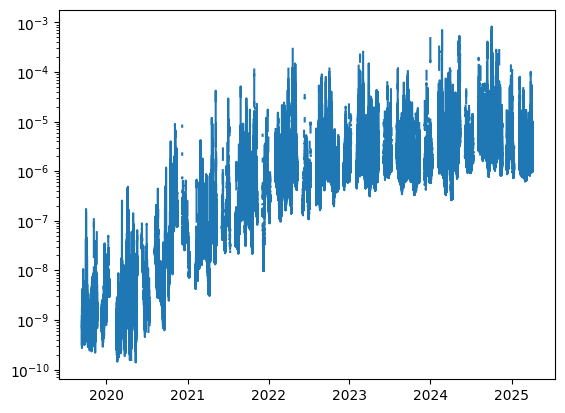

In [5]:
plt.plot(xsmDT,xsm_flux_1)
plt.yscale('log')
plt.show()

## Identification of flares and classification

**Task:** Plot the GOES XRS flux data and XSM flux data for different time periods (set the xlim of the plot as you desire) and identify flares of different flux classes - A, B, C, M, and X. Select one flare from each category and plot the X-ray flux data for the entire duration of the flare. 

An example is given below. You may also use the [XSM website](https://www.prl.res.in/ch2xsm/) to identify the flares easily. 

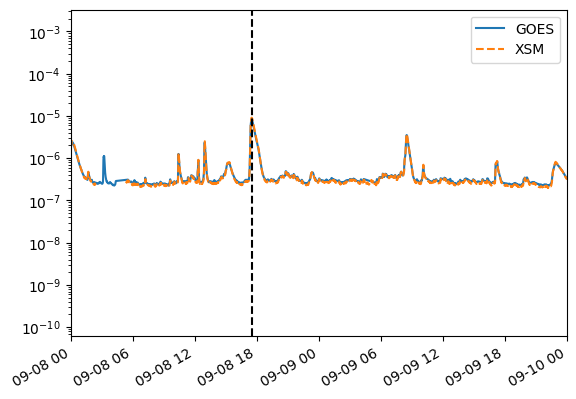

In [6]:
goesdfFilt['xrsb'].plot(label='GOES')
plt.plot(xsmDT,xsm_flux_1,color='C1',label='XSM',linestyle='dashed')
plt.xlim([datetime(2021,9,8),datetime(2021,9,10)])
plt.legend()
plt.yscale('log')
plt.axvline(datetime(2021,9,8,17,30),linestyle='dashed',color='black')
plt.show()

In the above light curve, we can see several flares. The strongest flare is around 17:30 on 08-Sep-21, which is a **C class** flare based on the flare peak intensity. Let us plot the X-ray flux light curve around that period to see this flare clearly.

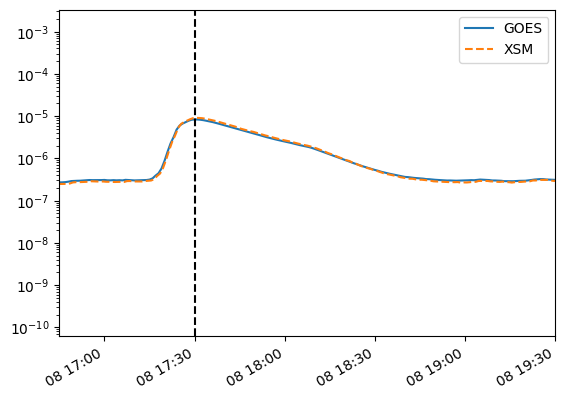

In [7]:
goesdfFilt['xrsb'].plot(label='GOES')
plt.plot(xsmDT,xsm_flux_1,color='C1',label='XSM',linestyle='dashed')
plt.xlim([datetime(2021,9,8,16,45),datetime(2021,9,8,19,30)])
plt.legend()
plt.yscale('log')
plt.axvline(datetime(2021,9,8,17,30),linestyle='dashed',color='black')
plt.show()

For XSM Spectral analysis of the above flare, see [this notebook](https://github.com/xastprl/xsm-analysis/blob/master/notebooks/ch2xsm_spectralFit_chspec_demo.ipynb)

## EUV Images of flares

Now, use [Helioviewer online tool](https://gs671-suske.ndc.nasa.gov/) to identify the location of these selected flares. Use the SDO AIA 94 Angstrom images. You may also use the images in other EUV bands of AIA. By looking through the sequence of images during the flare or by creating a movie, identify the flare location and see how the flare evolution is visible in EUV images. Download the image sequences or even a movie (perhaps for one case) from helioviewer for the selected flares of different classes. See how the EUV images of the events for different solar flare classes compare against each other. 

An example of a sequence of EUV images from SDO/AIA 94 Angstrom for the event shown above is given below for reference. 

![00](img/2021_09_08_17_00_00_AIA_94.png)
![01](img/2021_09_08_17_30_00_AIA_94.png)
![02](img/2021_09_08_17_40_00_AIA_94.png)
![03](img/2021_09_08_19_00_00_AIA_94.png)


<a id="appendix"></a>
# Appendix: Downloading X-ray flux data

## GOES XRS Data Download

GOES XRS flux in recent days can be seen from this [website](https://www.swpc.noaa.gov/products/goes-x-ray-flux). Data archive for the latest GOES series satellites are available at [this link](https://www.ncei.noaa.gov/products/goes-r-extreme-ultraviolet-xray-irradiance). 

The file used in this notebook is available for download at https://data.ngdc.noaa.gov/platforms/solar-space-observing-satellites/goes/goes16/l2/data/xrsf-l2-avg1m_science/

One can also use Sunpy package in python to directly download the GOES XRS data. A guide for this is available [here](https://docs.sunpy.org/en/stable/generated/gallery/time_series/goes_xrs_example.html).

## Chandrayaan-2 XSM Data Download

XSM flux for any period of observation can be seen using this [web application](https://www.prl.res.in/ch2xsm/).

XSM data is available for download from [PRADAN](https://pradan.issdc.gov.in/ch2/) portal of Indian Space Science Data Center (ISSDC). It may be noted that XSM provides spectral data and is available in FITS format and standard calibrated spectra at 1-minute cadence is available for download from the above archive. Tools to generate XSM flux light curves similar to the one used in this exercise are also provided; they may be downloaded from [here](https://www.prl.res.in/ch2xsm/data_analysis). For the usage of *xsmcomputeflux* module for this purpose is available in the [XSM Data Analysis Guide](https://www.prl.res.in/ch2xsm/static/ch2_xsm_data_analysis_guide.pdf). Please refer to Section 4.5.3 in the user guide.  
